# 03 · Quantum dependence model for synthetic tabular data

**QGAI open notebooks · Track: Quantum Synthetic Data**

Regulated teams often can't share real data, so they share **synthetic** data instead. The hard part is the *dependence
structure*, especially rare joint events, which classical generators tend to smooth away.

We build a small payments-style dataset with six yes/no features and a rare **"fraud ring" pattern**: fraud jumps sharply only when a payment
is foreign **and** at night **and** from a new device. That is a *three-way* interaction.

We fit six generators on 4,000 sampled records and score each against the **true** distribution, which we know exactly because we defined it:

| Generator | Captures |
|---|---|
| Independent columns | Each column's rate only |
| Gaussian copula | Pairwise correlations through a latent Gaussian (a standard synthetic-data method) |
| Pairwise Boltzmann machine | All pairwise interactions |
| Boltzmann machine + 3-way terms | Pairwise **and** three-way interactions: the strong classical baseline |
| QCBM (6 qubits) | Whatever a shallow 6-qubit circuit can represent, including higher-order correlations |
| Copy of training data | Everything, by **leaking the real records** (shown as a privacy warning, not a valid option) |

Scores (lower is better except where noted): total variation distance (TVD), and error on the rate of the rare fraud-ring event.
This notebook studies *fidelity* only; it adds no formal privacy guarantee (differential privacy is future work).

In [1]:
import itertools, time
import numpy as np
import pennylane as qml
from pennylane import numpy as pnp
from scipy.optimize import minimize, brentq
from scipy.stats import norm, multivariate_normal
import matplotlib.pyplot as plt

SEED = 3
rng = np.random.default_rng(SEED)
COLS = ["online", "foreign", "night", "new_device", "high_amount", "fraud"]
N = len(COLS)

## The true data-generating process
Each column depends on earlier ones; fraud has a small base rate plus a large jump for the three-way fraud-ring pattern.

In [2]:
def p_true_of(x):
    online, foreign, night, newdev, high, fraud = x
    def b(p, v): return p if v else 1 - p
    p = b(0.60, online)
    p *= b(0.15 + 0.10 * online, foreign)
    p *= b(0.25, night)
    p *= b(0.10 + 0.15 * online, newdev)
    p *= b(0.20 + 0.20 * foreign, high)
    p *= b(0.01 + 0.03 * high + 0.60 * (foreign * night * newdev), fraud)
    return p

states = np.array(list(itertools.product([0, 1], repeat=N)))
p_true = np.array([p_true_of(s) for s in states]); p_true /= p_true.sum()
ring = (states[:, 1] == 1) & (states[:, 2] == 1) & (states[:, 3] == 1) & (states[:, 5] == 1)
print(f"P(fraud) = {p_true[states[:, 5] == 1].sum():.3%}")
print(f"P(fraud ring: foreign & night & new device & fraud) = {p_true[ring].sum():.3%}")

TRAIN = 4000
sample_idx = rng.choice(len(states), size=TRAIN, p=p_true)
p_emp = np.bincount(sample_idx, minlength=len(states)) / TRAIN
print(f"training records: {TRAIN}, of which fraud-ring records: {int(ring[sample_idx].sum())}")

def tvd(p, q): return 0.5 * float(np.abs(p - q).sum())
def report(q):
    return dict(tvd=tvd(p_true, q), ring=float(q[ring].sum()), fraud=float(q[states[:, 5] == 1].sum()))
models = {}

P(fraud) = 2.378%
P(fraud ring: foreign & night & new device & fraud) = 0.676%
training records: 4000, of which fraud-ring records: 29


## 1. Independent columns

In [3]:
rates = p_emp @ states
q_ind = np.prod(np.where(states == 1, rates, 1 - rates), axis=1)
models["Independent columns"] = q_ind

## 2. Gaussian copula
Each column is 1 when a latent standard normal exceeds a threshold. Latent correlations are chosen so every *pairwise* joint rate matches the data; then we sample 400,000 latent vectors to get the model distribution.

In [4]:
thr = norm.ppf(1 - rates)
R = np.eye(N)
for i, j in itertools.combinations(range(N), 2):
    target = p_emp[(states[:, i] == 1) & (states[:, j] == 1)].sum()
    def gap(r):
        # P(Zi > ti, Zj > tj) = P(-Zi < -ti, -Zj < -tj)
        return multivariate_normal(mean=[0, 0], cov=[[1, r], [r, 1]]).cdf([-thr[i], -thr[j]]) - target
    R[i, j] = R[j, i] = brentq(gap, -0.99, 0.99)
w_, V = np.linalg.eigh(R); R = V @ np.diag(np.clip(w_, 1e-6, None)) @ V.T   # nearest positive-definite
Z = rng.multivariate_normal(np.zeros(N), R, size=400_000)
codes = (Z > thr).astype(int) @ (2 ** np.arange(N)[::-1])
models["Gaussian copula"] = np.bincount(codes, minlength=len(states)) / len(codes)

## 3. Pairwise Boltzmann machine (exact maximum likelihood on the training data)

In [5]:
spins = 2 * states - 1
pairs = list(itertools.combinations(range(N), 2))
feats = np.hstack([spins, np.stack([spins[:, i] * spins[:, j] for i, j in pairs], 1)])
def nll(w):
    e = feats @ w; logZ = np.logaddexp.reduce(e); q = np.exp(e - logZ)
    return -(p_emp @ (e - logZ)) + 1e-4 * w @ w, -(p_emp @ feats) + q @ feats + 2e-4 * w
w = minimize(nll, np.zeros(feats.shape[1]), jac=True, method="L-BFGS-B").x
e = feats @ w; models["Pairwise Boltzmann"] = np.exp(e - np.logaddexp.reduce(e))

## 3b. Boltzmann machine with three-way terms (strong classical baseline)
Same model plus a parameter for every triple of columns, so it *can* express the fraud-ring interaction directly.

In [6]:
triples = list(itertools.combinations(range(N), 3))
feats3 = np.hstack([feats, np.stack([spins[:, i] * spins[:, j] * spins[:, k] for i, j, k in triples], 1)])
def nll3(w):
    e = feats3 @ w; logZ = np.logaddexp.reduce(e); q = np.exp(e - logZ)
    return -(p_emp @ (e - logZ)) + 1e-4 * w @ w, -(p_emp @ feats3) + q @ feats3 + 2e-4 * w
w3 = minimize(nll3, np.zeros(feats3.shape[1]), jac=True, method="L-BFGS-B").x
e = feats3 @ w3; models["Boltzmann + 3-way terms"] = np.exp(e - np.logaddexp.reduce(e))
print(f"pairwise model: {feats.shape[1]} parameters; with 3-way terms: {feats3.shape[1]} parameters")

pairwise model: 21 parameters; with 3-way terms: 41 parameters


## 4. QCBM (6 qubits)
Same hardware-efficient ansatz as notebook 01, kept shallow (see notebook 02), trained on the empirical distribution with exact KL and Adam.

In [7]:
LAYERS = 4
dev = qml.device("default.qubit", wires=N)

@qml.qnode(dev, diff_method="backprop")
def qcbm(params):
    for l in range(LAYERS):
        for q in range(N):
            qml.RY(params[l, q, 0], wires=q); qml.RZ(params[l, q, 1], wires=q)
        for q in range(N):
            qml.CNOT(wires=[q, (q + 1) % N])
    for q in range(N):
        qml.RY(params[LAYERS, q, 0], wires=q)
    return qml.probs(wires=range(N))

target = pnp.array(p_emp, requires_grad=False); m = target > 0
def loss(params):
    q = qcbm(params)
    return pnp.sum(target[m] * (pnp.log(target[m]) - pnp.log(q[m] + 1e-10)))

def train_qcbm(seed, steps=500):
    np.random.seed(seed)
    params = pnp.array(np.random.uniform(0, 2 * np.pi, (LAYERS + 1, N, 2)), requires_grad=True)
    opt = qml.AdamOptimizer(0.05)
    for _ in range(steps):
        params = opt.step(loss, params)
    return np.asarray(qcbm(params))

t = time.time()
models["QCBM (6 qubits)"] = train_qcbm(SEED)
print(f"QCBM: {LAYERS * N * 2 + N} parameters, trained in {time.time() - t:.0f}s")

QCBM: 54 parameters, trained in 13s


## 5. Copy of the training data (privacy warning)

In [8]:
models["Copy of training data (leaks records)"] = p_emp

## Results against the true distribution

Generator                                  TVD   P(fraud)  P(fraud ring)  ring error
(true distribution)                      0.000     2.378%         0.676%            
Independent columns                      0.116     2.475%         0.026%        96%
Gaussian copula                          0.032     2.496%         0.177%        74%
Pairwise Boltzmann                       0.031     2.490%         0.205%        70%
Boltzmann + 3-way terms                  0.033     2.491%         0.599%        11%
QCBM (6 qubits)                          0.031     2.505%         0.676%         0%
Copy of training data (leaks records)    0.032     2.475%         0.725%         7%


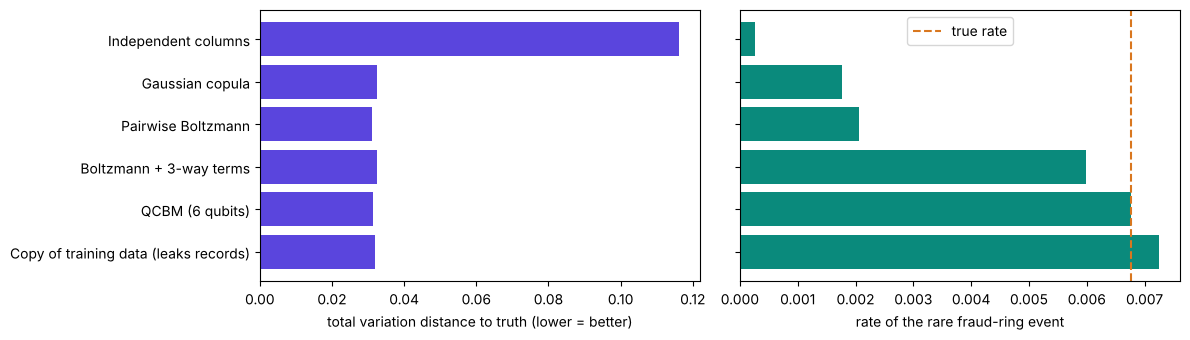

In [9]:
truth = report(p_true)
print(f"{'Generator':38s} {'TVD':>7s} {'P(fraud)':>10s} {'P(fraud ring)':>14s} {'ring error':>11s}")
print(f"{'(true distribution)':38s} {0:>7.3f} {truth['fraud']:>10.3%} {truth['ring']:>14.3%} {'':>11s}")
rows = {}
for name, q in models.items():
    r = report(q); rows[name] = r
    print(f"{name:38s} {r['tvd']:>7.3f} {r['fraud']:>10.3%} {r['ring']:>14.3%} {abs(r['ring'] - truth['ring']) / truth['ring']:>10.0%}")

names = list(models)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].barh(names, [rows[n]["tvd"] for n in names], color="#5a45dd"); axes[0].invert_yaxis()
axes[0].set_xlabel("total variation distance to truth (lower = better)")
axes[1].barh(names, [rows[n]["ring"] for n in names], color="#0a8a7c"); axes[1].invert_yaxis()
axes[1].axvline(truth["ring"], color="#d9771f", ls="--", label="true rate"); axes[1].legend()
axes[1].set_xlabel("rate of the rare fraud-ring event"); axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()

## Robustness: is the QCBM result a lucky seed?
Retrain the QCBM from five different random initialisations and look at the spread.

In [10]:
seed_rows = []
for sd in [3, 11, 23, 37, 51]:
    r = report(train_qcbm(sd)); seed_rows.append(r)
    print(f"seed {sd:>2}: TVD {r['tvd']:.3f}   P(fraud ring) {r['ring']:.3%}   ring error {abs(r['ring'] - truth['ring']) / truth['ring']:.0%}")
errs = np.array([abs(r["ring"] - truth["ring"]) / truth["ring"] for r in seed_rows])
tv = np.array([r["tvd"] for r in seed_rows])
print(f"\nacross 5 seeds: TVD {tv.mean():.3f} ± {tv.std():.3f};  fraud-ring error {errs.mean():.0%} ± {errs.std():.0%}")

seed  3: TVD 0.031   P(fraud ring) 0.676%   ring error 0%


seed 11: TVD 0.032   P(fraud ring) 0.653%   ring error 3%


seed 23: TVD 0.032   P(fraud ring) 0.633%   ring error 6%


seed 37: TVD 0.033   P(fraud ring) 0.628%   ring error 7%


seed 51: TVD 0.035   P(fraud ring) 0.686%   ring error 1%

across 5 seeds: TVD 0.033 ± 0.001;  fraud-ring error 4% ± 3%


## Reading the results honestly

- **Overall fidelity is a tie.** Apart from independent columns, every generator lands at a TVD of about 0.03. Headline "distance" metrics hide the interesting differences.
- **The rare fraud-ring event separates the models.** The Gaussian copula and the pairwise Boltzmann machine under-estimate it by about 70%, because no pairwise model can express a three-way interaction. Fraud-detection models trained on their synthetic data would barely see the pattern.
- **Higher-order models capture it, quantum and classical alike.** The QCBM misses the true rate by about 4% ± 3% across five seeds; the classical Boltzmann machine with explicit three-way terms misses by about 11%.
- **That gap is within noise.** The training set holds only 29 fraud-ring records, so the rate a model can learn is itself uncertain by roughly ±19% ($1/\sqrt{29}$). We do **not** claim the QCBM beats the three-way classical model.
- **The copy of the training data** looks good on every metric, and it is the worst option: it *is* the real records. Fidelity without privacy is not synthetic data.

**What this supports:** entangling circuits can represent higher-order dependence that the most common synthetic-data method (the Gaussian copula) structurally cannot. **What it does not support:** a quantum advantage. A classical model given the right interaction terms does about as well, and at 6 binary columns everything here is cheap to compute classically.

**Try next:** more columns (where enumerating all interaction terms classically gets expensive), held-out evaluation, train-on-synthetic / test-on-real fraud classifiers, and differential-privacy accounting.